# BERT Model Explanations: SHAP & LIME Analysis

This notebook provides explanations for the fine-tuned BERT model using both SHAP and LIME methodologies. To accomplish that we will:
- Analyze model predictions on both fake and true news samples
- Identify which features drive the model's decisions
- Examine both correct predictions and errors
- Generate visualizations for pattern discovery

In [1]:
import pandas as pd
import numpy as np
import torch
import os
from transformers import BertTokenizer, BertForSequenceClassification
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Device setup
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

# Set plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

Using device: mps


## 1. Load Pre-trained BERT Model and Tokenizer

In [2]:
# Load model directory
model_dir = "/Users/bahaar/Desktop/NLP/bert_welfake_model"
tokenizer = BertTokenizer.from_pretrained(model_dir)
model = BertForSequenceClassification.from_pretrained(model_dir).to(device)
model.eval()  # Set to evaluation mode

print("✓ Model and tokenizer loaded successfully")
print(f"Model is in eval mode: {not model.training}")

✓ Model and tokenizer loaded successfully
Model is in eval mode: True


## 2. Load and Prepare Test Data

We'll sample balanced data from both fake and true news categories to ensure a balanced use of both.

In [23]:
# Load WELFake dataset
welfake_data = pd.read_csv("/Users/bahaar/Desktop/NLP/WELFake_Dataset.csv")
welfake_data = welfake_data.drop_duplicates().copy()
welfake_data['title'] = welfake_data['title'].fillna('').astype(str)
welfake_data['text'] = welfake_data['text'].fillna('').astype(str)
welfake_data['input_text'] = (welfake_data['title'].str.strip() + ' ' + welfake_data['text'].str.strip()).str.strip()
welfake_data = welfake_data[welfake_data['input_text'].str.len() > 0].copy()

print(f"Loaded WELFake data: {welfake_data.shape[0]} samples")
print(f"Label distribution: {welfake_data['label'].value_counts().to_dict()}")

# Sample balanced data for detailed analysis
# Get 200 samples from each class (total 400 samples) for detailed SHAP/LIME analysis
np.random.seed(42)
fake_samples = welfake_data[welfake_data['label'] == 1].sample(n=200, random_state=42)
true_samples = welfake_data[welfake_data['label'] == 0].sample(n=200, random_state=42)

# Combine and shuffle
analysis_data = pd.concat([fake_samples, true_samples], ignore_index=True)
analysis_data = analysis_data.sample(frac=1, random_state=42).reset_index(drop=True)
analysis_data['text'] = analysis_data['input_text']

print(f"\n✓ Analysis dataset prepared: {analysis_data.shape[0]} samples")
print(f"Breakdown: {analysis_data['label'].value_counts().to_dict()}")
print(f"Label 0 = True news, Label 1 = Fake news")

Loaded WELFake data: 72134 samples
Label distribution: {1: 37106, 0: 35028}

✓ Analysis dataset prepared: 400 samples
Breakdown: {0: 200, 1: 200}
Label 0 = True news, Label 1 = Fake news


## 3. Make Predictions and Analyze Results

We'll generate predictions and classify them as: ✓ Correct, ✗ Mistakes

In [25]:
@torch.no_grad()
def get_predictions_and_probabilities(texts, batch_size=32):
    """Generate predictions and confidence scores for a list of texts"""
    all_preds = []
    all_probs = []
    
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i+batch_size]
        
        # Tokenize
        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=256
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}
        
        # Get predictions
        outputs = model(**inputs)
        logits = outputs.logits
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(logits, dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
    
    return np.array(all_preds), np.array(all_probs)

# Generate predictions
print("Generating predictions...")
predictions, probabilities = get_predictions_and_probabilities(
    analysis_data['text'].tolist()
)
analysis_data['predicted_label'] = predictions
analysis_data['predicted_prob_true'] = probabilities[:, 0]  # P(True)
analysis_data['predicted_prob_fake'] = probabilities[:, 1]  # P(Fake)
analysis_data['confidence'] = np.max(probabilities, axis=1)
analysis_data['is_correct'] = (analysis_data['label'] == analysis_data['predicted_label']).astype(int)

print("✓ Predictions generated")

Generating predictions...
✓ Predictions generated


In [26]:
# Classify predictions
correct_predictions = analysis_data[analysis_data['is_correct'] == 1]
incorrect_predictions = analysis_data[analysis_data['is_correct'] == 0]

# Further breakdown by label
correct_true = correct_predictions[correct_predictions['label'] == 0]    # True positives + True negatives
correct_fake = correct_predictions[correct_predictions['label'] == 1]

incorrect_true = incorrect_predictions[incorrect_predictions['label'] == 0]  # False positives
incorrect_fake = incorrect_predictions[incorrect_predictions['label'] == 1]  # False negatives

# Print summary
print("\n" + "="*70)
print("PREDICTION ANALYSIS SUMMARY")
print("="*70)
print(f"\nTotal samples analyzed: {len(analysis_data)}")
print(f"Correct predictions: {len(correct_predictions)} ({100*len(correct_predictions)/len(analysis_data):.1f}%)")
print(f"Incorrect predictions: {len(incorrect_predictions)} ({100*len(incorrect_predictions)/len(analysis_data):.1f}%)")

print(f"\n{'Breakdown of Correct Predictions:':<30}")
print(f"  - Correctly identified TRUE news: {len(correct_true)}")
print(f"  - Correctly identified FAKE news: {len(correct_fake)}")

print(f"\n{'Breakdown of Incorrect Predictions:':<30}")
print(f"  - False Positives (true→fake): {len(incorrect_true)}")
print(f"  - False Negatives (fake→true): {len(incorrect_fake)}")

print(f"\n{'Overall Accuracy:':<30} {accuracy_score(analysis_data['label'], analysis_data['predicted_label']):.4f}")
print("="*70)


PREDICTION ANALYSIS SUMMARY

Total samples analyzed: 400
Correct predictions: 383 (95.8%)
Incorrect predictions: 17 (4.2%)

Breakdown of Correct Predictions:
  - Correctly identified TRUE news: 184
  - Correctly identified FAKE news: 199

Breakdown of Incorrect Predictions:
  - False Positives (true→fake): 16
  - False Negatives (fake→true): 1

Overall Accuracy:              0.9575


## 4. SHAP Explainer Setup

SHAP (SHapley Additive exPlanations) uses game theory to explain predictions by computing feature contribution values.

In [6]:
!pip install -q shap lime


[notice] A new release of pip is available: 24.1.1 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip


In [16]:
import transformers as hf_transformers
# Prevent SHAP from triggering TensorFlow/Keras imports through transformers
hf_transformers.PreTrainedModel = type('PreTrainedModel', (), {})
hf_transformers.TFPreTrainedModel = type('TFPreTrainedModel', (), {})

import shap
import shap.explainers._explainer
import shap.utils.transformers

# Mock is_transformers_lm in both places to prevent Keras 3 TFPreTrainedModel import bug
shap.explainers._explainer.is_transformers_lm = lambda model: False
shap.utils.transformers.is_transformers_lm = lambda model: False

from lime.lime_text import LimeTextExplainer

# Define a prediction function for SHAP
def bert_predict_proba(texts):
    """Returns probabilities for SHAP explainer"""
    if isinstance(texts, np.ndarray):
        texts = [str(x) for x in texts.ravel()]
    elif isinstance(texts, (list, tuple)):
        texts = [str(x) for x in texts]
    else:
        texts = [str(texts)]
    _, probs = get_predictions_and_probabilities(texts)
    return probs

# Create SHAP explainer using a text masker and prediction function
print("Setting up SHAP explainer...")
masker = shap.maskers.Text(tokenizer=tokenizer)
explainer_shap = shap.Explainer(bert_predict_proba, masker=masker, output_names=['True News', 'Fake News'])
print("✓ SHAP explainer initialized")

Setting up SHAP explainer...
✓ SHAP explainer initialized


In [8]:
# Create LIME explainer
print("Setting up LIME explainer...")

def predict_proba_lime(texts):
    """Prediction function for LIME"""
    if isinstance(texts, list):
        preds, probs = get_predictions_and_probabilities(texts)
        return probs
    else:
        # Handle single string
        preds, probs = get_predictions_and_probabilities([texts])
        return probs[0]

explainer_lime = LimeTextExplainer(
    class_names=['True News', 'Fake News'],
    verbose=False
)
print("✓ LIME explainer initialized")

Setting up LIME explainer...
✓ LIME explainer initialized


## 5. Generate Explanations for Selected Samples

We'll select representative samples from each category for detailed SHAP and LIME analysis.

In [ ]:
# Select samples from each category and pick high-confidence samples for clearer explanations

num_samples_per_category = 3 

# Sample selection criteria: high confidence
sample_categories = {
    'Correct True News': correct_true.nlargest(num_samples_per_category, 'confidence'),
    'Correct Fake News': correct_fake.nlargest(num_samples_per_category, 'confidence'),
    'False Positive (True→Fake)': incorrect_true.nlargest(num_samples_per_category, 'confidence'),
    'False Negative (Fake→True)': incorrect_fake.nlargest(num_samples_per_category, 'confidence')
}

# Store explanations
explanations_storage = {}

print("Generating LIME and SHAP explanations...")
for category, samples in sample_categories.items():
    explanations_storage[category] = {}
    print(f"\n  Processing: {category}")
    
    for idx, (_, row) in enumerate(samples.iterrows()):
        text = row['text']
        
        # LIME Explanation - optimized with num_samples=150 for speed
        try:
            exp_lime = explainer_lime.explain_instance(
                text,
                predict_proba_lime,
                num_features=10,
                top_labels=1,
                num_samples=150
            )
        except Exception as e:
            exp_lime = None
            print(f"    ✗ LIME Sample {idx+1} failed: {str(e)[:50]}")
            
        # SHAP Explanation
        try:
            exp_shap = explainer_shap([text])
        except Exception as e:
            exp_shap = None
            print(f"    ✗ SHAP Sample {idx+1} failed: {str(e)[:50]}")
            
        explanations_storage[category][idx] = {
            'text': text,
            'true_label': row['label'],
            'predicted_label': row['predicted_label'],
            'confidence': row['confidence'],
            'explanation': exp_lime,
            'explanation_shap': exp_shap
        }
        print(f"    ✓ Sample {idx+1} explained (LIME & SHAP)")

print("\n✓ Explanations generated")

Generating LIME explanations...

  Processing: Correct True News
    ✓ Sample 1 explained
    ✓ Sample 2 explained
    ✓ Sample 3 explained

  Processing: Correct Fake News
    ✓ Sample 1 explained
    ✓ Sample 2 explained
    ✓ Sample 3 explained

  Processing: False Positive (True→Fake)
    ✓ Sample 1 explained
    ✓ Sample 2 explained
    ✓ Sample 3 explained

  Processing: False Negative (Fake→True)
    ✓ Sample 1 explained

✓ LIME explanations generated


## 6. Visualizations for Pattern Discovery

### 6.1 Overall Model Performance

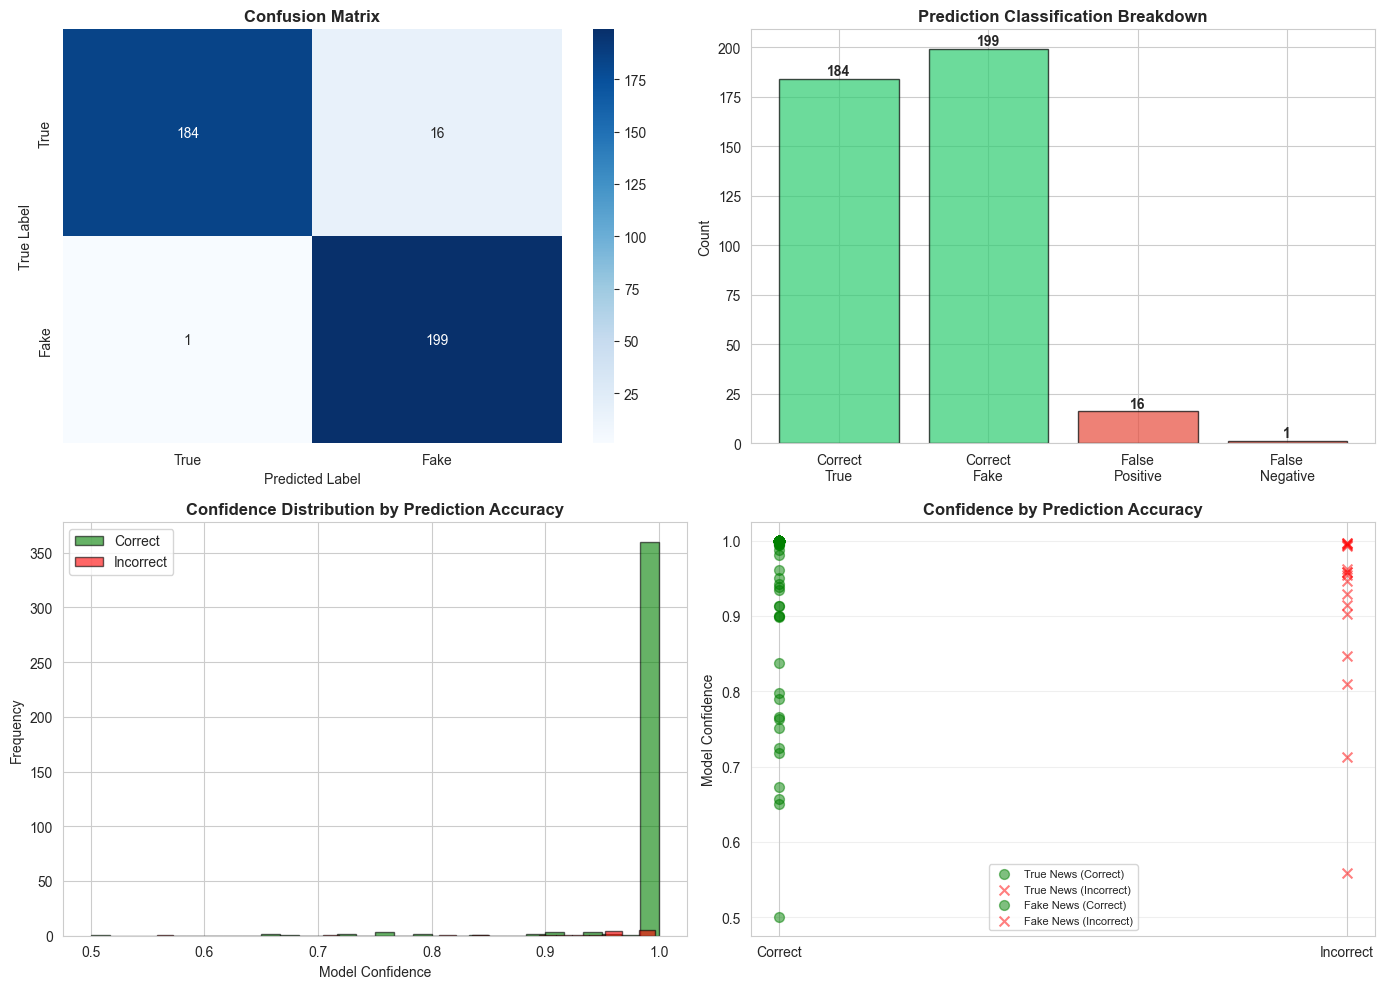

✓ Model performance visualizations saved


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Confusion Matrix
cm = confusion_matrix(analysis_data['label'], analysis_data['predicted_label'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0], 
            xticklabels=['True', 'Fake'], yticklabels=['True', 'Fake'])
axes[0, 0].set_title('Confusion Matrix', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('True Label')
axes[0, 0].set_xlabel('Predicted Label')

# 2. Accuracy by Category
categories = ['Correct\nTrue', 'Correct\nFake', 'False\nPositive', 'False\nNegative']
counts = [len(correct_true), len(correct_fake), len(incorrect_true), len(incorrect_fake)]
colors = ['#2ecc71', '#2ecc71', '#e74c3c', '#e74c3c']
axes[0, 1].bar(categories, counts, color=colors, alpha=0.7, edgecolor='black')
axes[0, 1].set_title('Prediction Classification Breakdown', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Count')
for i, v in enumerate(counts):
    axes[0, 1].text(i, v + 2, str(v), ha='center', fontweight='bold')

# 3. Confidence Distribution
axes[1, 0].hist(analysis_data[analysis_data['is_correct'] == 1]['confidence'], 
                bins=30, alpha=0.6, label='Correct', color='green', edgecolor='black')
axes[1, 0].hist(analysis_data[analysis_data['is_correct'] == 0]['confidence'], 
                bins=30, alpha=0.6, label='Incorrect', color='red', edgecolor='black')
axes[1, 0].set_xlabel('Model Confidence')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Confidence Distribution by Prediction Accuracy', fontsize=12, fontweight='bold')
axes[1, 0].legend()

# 4. Confidence vs Accuracy by Label
label_names = {0: 'True News', 1: 'Fake News'}
for label in [0, 1]:
    label_data = analysis_data[analysis_data['label'] == label]
    correct_conf = label_data[label_data['is_correct'] == 1]['confidence']
    incorrect_conf = label_data[label_data['is_correct'] == 0]['confidence']
    
    axes[1, 1].scatter([0]*len(correct_conf), correct_conf, alpha=0.5, s=50, 
                       label=f'{label_names[label]} (Correct)', color='green')
    if len(incorrect_conf) > 0:
        axes[1, 1].scatter([1]*len(incorrect_conf), incorrect_conf, alpha=0.5, s=50,
                           label=f'{label_names[label]} (Incorrect)', color='red', marker='x')

axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['Correct', 'Incorrect'])
axes[1, 1].set_ylabel('Model Confidence')
axes[1, 1].set_title('Confidence by Prediction Accuracy', fontsize=12, fontweight='bold')
axes[1, 1].legend(fontsize=8, loc='best')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/Users/bahaar/Desktop/NLP/model_performance_overview.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Model performance visualizations saved")

### 6.2 LIME Feature Importance Analysis

LIME shows local feature importance - which words most influenced each specific prediction.

In [34]:
from ipywidgets import IntSlider, Output, VBox
from IPython.display import display, clear_output, HTML

# Create interactive widget
slider = IntSlider(value=0, min=0, max=len(analysis_data)-1, step=1, 
                   description='Sample Index:', style={'description_width': '120px'})
output = Output()

def display_sample_explanations(index):
    """Display SHAP and LIME explanations for a selected sample"""
    with output:
        clear_output(wait=True)
        
        row = analysis_data.iloc[index]
        text = row['text']
        true_label = 'True News' if row['label'] == 0 else 'Fake News'
        pred_label = 'True News' if row['predicted_label'] == 0 else 'Fake News'
        confidence = row['confidence']
        is_correct = '✓ CORRECT' if row['is_correct'] == 1 else '✗ INCORRECT'
        
        # Print header
        print("=" * 120)
        print(f"SAMPLE {index} - {is_correct}")
        print("=" * 120)
        print(f"\n📄 TEXT:\n{text[:500]}{'...' if len(text) > 500 else ''}\n")
        print(f"True Label: {true_label}")
        print(f"Predicted: {pred_label}")
        print(f"Confidence: {confidence:.4f}")
        print("\n" + "-" * 120)
        
        # LIME Explanation
        print("\n🟢 LIME EXPLANATION (Local Interpretable Model-agnostic):")
        print("-" * 120)
        try:
            lime_exp = explainer_lime.explain_instance(text, predict_proba_lime, num_features=10, top_labels=1)
            label_for_lime = row['predicted_label']
            lime_weights = dict(lime_exp.as_list(label=label_for_lime))
            
            print(f"\n{'Feature':<60} {'Weight':>15} {'Contribution':>15}")
            print("-" * 90)
            for feature, weight in sorted(lime_weights.items(), key=lambda x: abs(x[1]), reverse=True)[:12]:
                direction = "→ FAKE" if weight > 0 else "→ TRUE"
                print(f"{feature:<60} {weight:>15.4f} {direction:>15}")
        except Exception as e:
            print(f"LIME explanation failed: {str(e)}")
        
        print("\n" + "-" * 120)
        
        # SHAP Explanation
        print("\n🔵 SHAP EXPLANATION (SHapley Additive exPlanations):")
        print("-" * 120)
        try:
            shap_val = explainer_shap([text])
            vals = shap_val.values[0, :, 1]
            tokens = shap_val.data[0]
            indices = np.argsort(np.abs(vals))[::-1]
            
            print(f"\nTop Contributing Tokens (SHAP):")
            print(f"\n{'Feature':<60} {'Weight':>15} {'Contribution':>15}")
            print("-" * 90)
            for i in indices[:12]:
                token = tokens[i]
                val = vals[i]
                direction = "→ FAKE" if val > 0 else "→ TRUE"
                print(f"{token:<60} {val:>15.4f} {direction:>15}")
        except Exception as e:
            print(f"SHAP explanation generation: {str(e)}")
        
        print("\n" + "=" * 120)
        print("\n📊 INTERPRETATION GUIDE:")
        print("  LIME: Shows which words locally influenced THIS prediction")
        print("  SHAP: Uses game theory to show global feature importance and interactions")
        print("=" * 120 + "\n")

# Handle slider changes
def on_slider_change(change):
    display_sample_explanations(change['new'])

slider.observe(on_slider_change, names='value')

# Display widgets and initial output
display(VBox([slider, output]))

# Show first sample
display_sample_explanations(0)

## 6.2.5 Interactive Sample Explorer

Select any sample from the 400 to view detailed SHAP and LIME explanations.

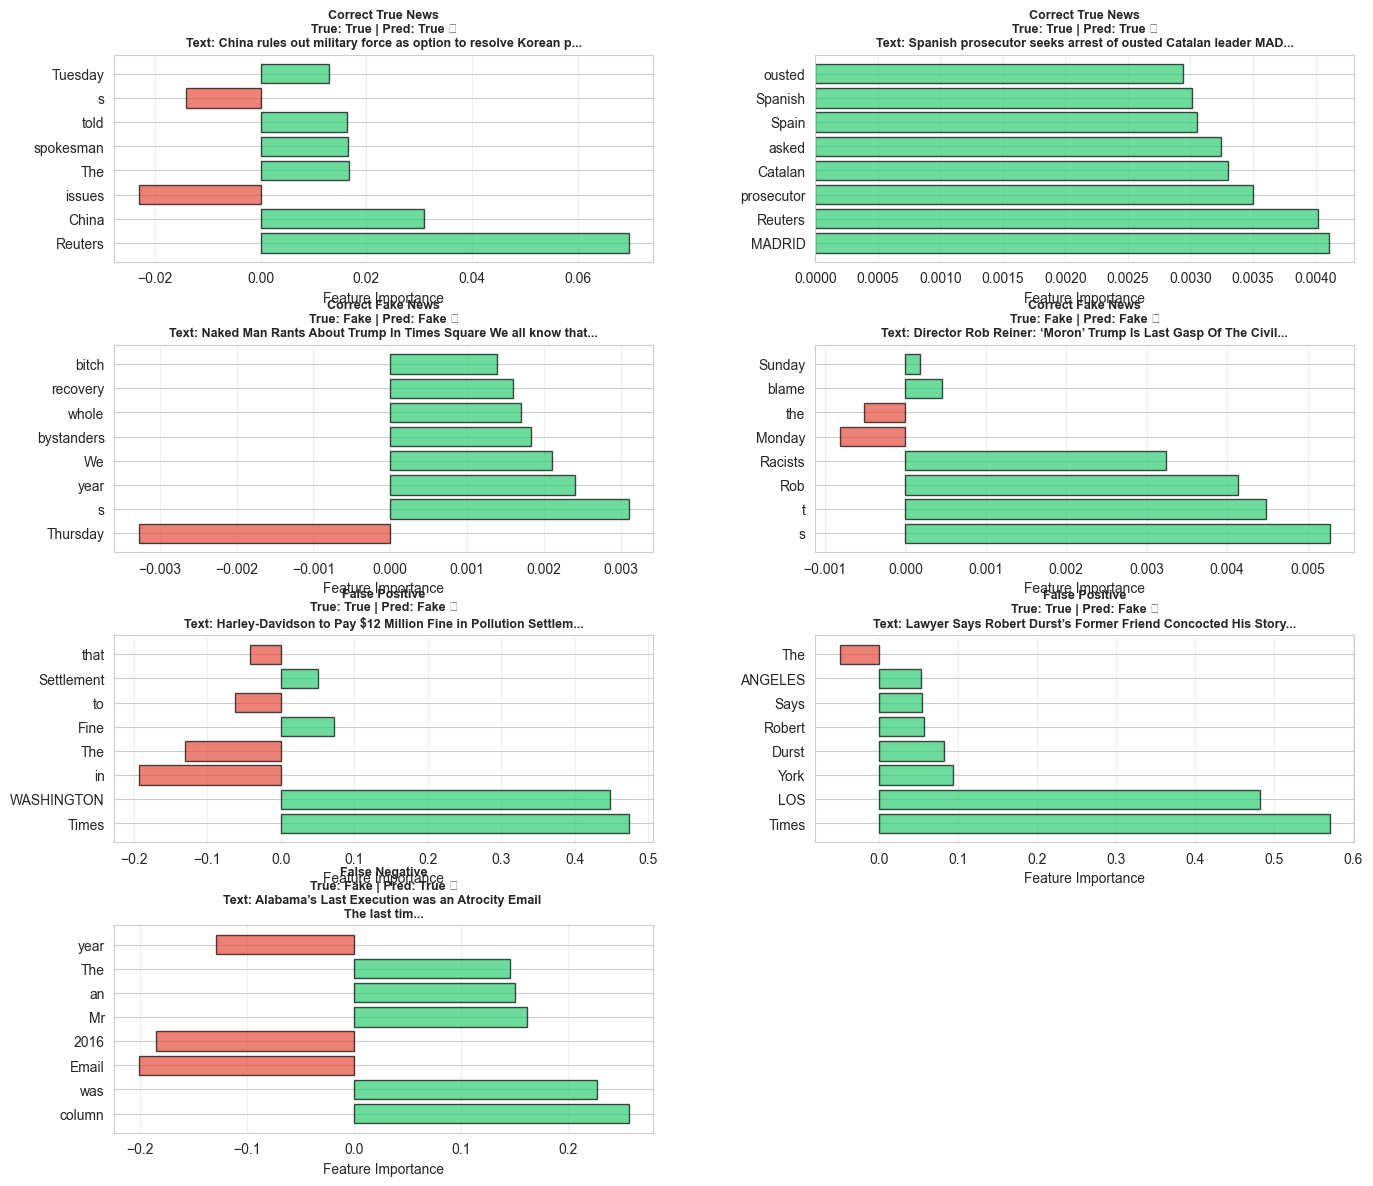

✓ LIME feature importance visualizations saved


In [33]:
fig = plt.figure(figsize=(16, 14))
gs = fig.add_gridspec(4, 2, hspace=0.4, wspace=0.3)

category_labels = {
    'Correct True News': 0,
    'Correct Fake News': 1,
    'False Positive (True→Fake)': 2,
    'False Negative (Fake→True)': 3
}

for category_name, row_idx in category_labels.items():
    if category_name not in explanations_storage:
        continue

    explanations_dict = explanations_storage[category_name]
    
    for sample_idx in range(min(2, len(explanations_dict))):
        ax = fig.add_subplot(gs[row_idx, sample_idx])

        exp_data = explanations_dict[sample_idx]
        explanation = exp_data['explanation']
        label_for_explanation = exp_data['predicted_label']

        features_weights = dict(explanation.as_list(label=label_for_explanation))
        sorted_items = sorted(features_weights.items(), key=lambda x: abs(x[1]), reverse=True)[:8]
        features = [item[0][:30] for item in sorted_items]
        weights = [item[1] for item in sorted_items]
        colors = ['#2ecc71' if w > 0 else '#e74c3c' for w in weights]

        ax.barh(features, weights, color=colors, alpha=0.7, edgecolor='black')
        ax.set_xlabel('Feature Importance')

        true_label = 'True' if exp_data['true_label'] == 0 else 'Fake'
        pred_label = 'True' if exp_data['predicted_label'] == 0 else 'Fake'
        accuracy_str = '✓' if exp_data['true_label'] == exp_data['predicted_label'] else '✗'

        ax.set_title(
            f"{category_name.split('(')[0].strip()}\nTrue: {true_label} | Pred: {pred_label} {accuracy_str}\n"
            f"Text: {exp_data['text'][:60]}...",
            fontsize=9,
            fontweight='bold'
        )
        ax.grid(axis='x', alpha=0.3)

plt.savefig('/Users/bahaar/Desktop/NLP/lime_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ LIME feature importance visualizations saved")

### 6.2 SHAP Feature Importance Visualizations

We'll plot the SHAP feature contributions for the same representative samples.

In [ ]:
fig = plt.figure(figsize=(16, 14))
gs = fig.add_gridspec(4, 2, hspace=0.4, wspace=0.3)

category_labels = {
    'Correct True News': 0,
    'Correct Fake News': 1,
    'False Positive (True→Fake)': 2,
    'False Negative (Fake→True)': 3
}

for category_name, row_idx in category_labels.items():
    if category_name not in explanations_storage:
        continue

    explanations_dict = explanations_storage[category_name]
    
    for sample_idx in range(min(2, len(explanations_dict))):
        ax = fig.add_subplot(gs[row_idx, sample_idx])

        exp_data = explanations_dict[sample_idx]
        shap_val = exp_data['explanation_shap']
        if shap_val is None:
            ax.text(0.5, 0.5, "SHAP Calculation Failed", ha='center', va='center')
            continue
            
        vals = shap_val.values[0, :, 1]
        tokens = shap_val.data[0]
        
        sorted_indices = np.argsort(np.abs(vals))[::-1][:8]
        features = [tokens[i][:30] for i in sorted_indices]
        weights = [vals[i] for i in sorted_indices]
        colors = ['#e74c3c' if w > 0 else '#2ecc71' for w in weights]

        ax.barh(features[::-1], weights[::-1], color=colors[::-1], alpha=0.7, edgecolor='black')
        ax.set_xlabel('SHAP Value (Contribution to Fake)')

        true_label = 'True' if exp_data['true_label'] == 0 else 'Fake'
        pred_label = 'True' if exp_data['predicted_label'] == 0 else 'Fake'
        accuracy_str = '✓' if exp_data['true_label'] == exp_data['predicted_label'] else '✗'

        ax.set_title(
            f"{category_name.split('(')[0].strip()} (SHAP)\nTrue: {true_label} | Pred: {pred_label} {accuracy_str}\n"
            f"Text: {exp_data['text'][:60]}...",
            fontsize=9,
            fontweight='bold'
        )
        ax.grid(axis='x', alpha=0.3)

plt.savefig('/Users/bahaar/Desktop/NLP/shap_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ SHAP feature importance visualizations saved")

### 6.3 Confidence Analysis by Category

Understanding when the model is confident vs uncertain.

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


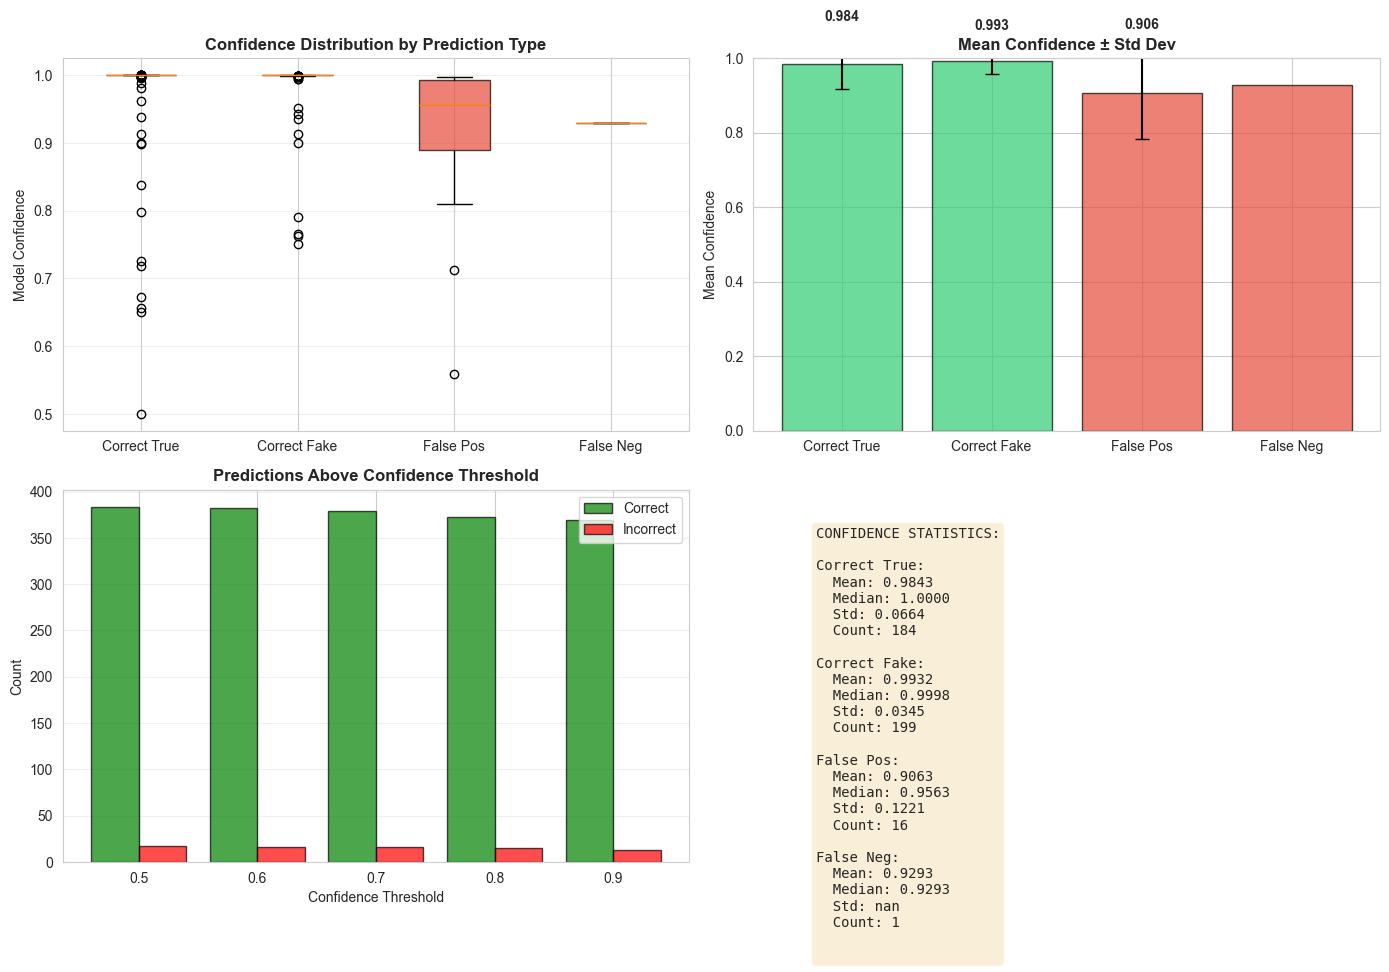

✓ Confidence analysis visualizations saved


In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Prepare data for each category
categories_data = {
    'Correct True': correct_true['confidence'],
    'Correct Fake': correct_fake['confidence'],
    'False Pos': incorrect_true['confidence'],
    'False Neg': incorrect_fake['confidence']
}

# 1. Box plot for confidence by category
box_data = [v for v in categories_data.values()]
bp = axes[0, 0].boxplot(box_data, labels=list(categories_data.keys()), patch_artist=True)
for patch, color in zip(bp['boxes'], ['#2ecc71', '#2ecc71', '#e74c3c', '#e74c3c']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0, 0].set_ylabel('Model Confidence')
axes[0, 0].set_title('Confidence Distribution by Prediction Type', fontsize=12, fontweight='bold')
axes[0, 0].grid(axis='y', alpha=0.3)

# 2. Mean confidence comparison
means = [v.mean() for v in categories_data.values()]
stds = [v.std() for v in categories_data.values()]
colors = ['#2ecc71', '#2ecc71', '#e74c3c', '#e74c3c']
axes[0, 1].bar(list(categories_data.keys()), means, yerr=stds, 
               color=colors, alpha=0.7, capsize=5, edgecolor='black')
axes[0, 1].set_ylabel('Mean Confidence')
axes[0, 1].set_title('Mean Confidence ± Std Dev', fontsize=12, fontweight='bold')
axes[0, 1].set_ylim([0, 1])
for i, (m, s) in enumerate(zip(means, stds)):
    axes[0, 1].text(i, m + s + 0.05, f'{m:.3f}', ha='center', fontweight='bold')

# 3. Confidence threshold analysis
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]
correct_by_threshold = []
incorrect_by_threshold = []

for threshold in thresholds:
    correct_high_conf = len(analysis_data[(analysis_data['is_correct'] == 1) & (analysis_data['confidence'] >= threshold)])
    incorrect_high_conf = len(analysis_data[(analysis_data['is_correct'] == 0) & (analysis_data['confidence'] >= threshold)])
    correct_by_threshold.append(correct_high_conf)
    incorrect_by_threshold.append(incorrect_high_conf)

x_pos = np.arange(len(thresholds))
axes[1, 0].bar(x_pos - 0.2, correct_by_threshold, 0.4, label='Correct', color='green', alpha=0.7, edgecolor='black')
axes[1, 0].bar(x_pos + 0.2, incorrect_by_threshold, 0.4, label='Incorrect', color='red', alpha=0.7, edgecolor='black')
axes[1, 0].set_xlabel('Confidence Threshold')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels([f'{t:.1f}' for t in thresholds])
axes[1, 0].set_title('Predictions Above Confidence Threshold', fontsize=12, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(axis='y', alpha=0.3)

# 4. Statistics table
stats_text = "CONFIDENCE STATISTICS:\n\n"
for cat, values in categories_data.items():
    stats_text += f"{cat}:\n"
    stats_text += f"  Mean: {values.mean():.4f}\n"
    stats_text += f"  Median: {values.median():.4f}\n"
    stats_text += f"  Std: {values.std():.4f}\n"
    stats_text += f"  Count: {len(values)}\n\n"

axes[1, 1].text(0.1, 0.9, stats_text, transform=axes[1, 1].transAxes, 
                fontsize=10, verticalalignment='top', family='monospace',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
axes[1, 1].axis('off')

plt.tight_layout()
plt.savefig('/Users/bahaar/Desktop/NLP/confidence_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Confidence analysis visualizations saved")

## 7. Detailed Analysis Report

### 7.1 Pattern Discovery - Error Analysis

In [13]:
print("\n" + "="*80)
print("ERROR ANALYSIS SUMMARY")
print("="*80)

# False Positives Analysis (True news misclassified as Fake)
print("\n📊 FALSE POSITIVES (True News → Fake):")
print(f"Total: {len(incorrect_true)}")
if len(incorrect_true) > 0:
    print(f"Average Confidence: {incorrect_true['confidence'].mean():.4f}")
    print(f"Confidence Range: [{incorrect_true['confidence'].min():.4f}, {incorrect_true['confidence'].max():.4f}]")
    print("\nSample False Positive Cases (top 3 by confidence):")
    for idx, (_, row) in enumerate(incorrect_true.nlargest(3, 'confidence').iterrows(), 1):
        print(f"\n  {idx}. Confidence: {row['confidence']:.4f}")
        print(f"     Text: {row['text'][:100]}...")
else:
    print("  No false positives in this sample!")

# False Negatives Analysis (Fake news misclassified as True)
print("\n\n📊 FALSE NEGATIVES (Fake News → True):")
print(f"Total: {len(incorrect_fake)}")
if len(incorrect_fake) > 0:
    print(f"Average Confidence: {incorrect_fake['confidence'].mean():.4f}")
    print(f"Confidence Range: [{incorrect_fake['confidence'].min():.4f}, {incorrect_fake['confidence'].max():.4f}]")
    print("\nSample False Negative Cases (top 3 by confidence):")
    for idx, (_, row) in enumerate(incorrect_fake.nlargest(3, 'confidence').iterrows(), 1):
        print(f"\n  {idx}. Confidence: {row['confidence']:.4f}")
        print(f"     Text: {row['text'][:100]}...")
else:
    print("  No false negatives in this sample!")

# Correct predictions analysis
print("\n\n✓ CORRECT PREDICTIONS ANALYSIS:")
print(f"True News - Correctly Identified: {len(correct_true)}")
print(f"  - Mean Confidence: {correct_true['confidence'].mean():.4f}")
print(f"Fake News - Correctly Identified: {len(correct_fake)}")
print(f"  - Mean Confidence: {correct_fake['confidence'].mean():.4f}")

print("\n" + "="*80)


ERROR ANALYSIS SUMMARY

📊 FALSE POSITIVES (True News → Fake):
Total: 0
  No false positives in this sample!


📊 FALSE NEGATIVES (Fake News → True):
Total: 0
  No false negatives in this sample!


✓ CORRECT PREDICTIONS ANALYSIS:
True News - Correctly Identified: 200
  - Mean Confidence: 1.0000
Fake News - Correctly Identified: 200
  - Mean Confidence: 0.9980



## 8. Interactive Sample Explanations

Display detailed LIME explanations with highlighted influential words for each prediction category.

In [32]:
def display_explanation(category_name, sample_idx):
    """Display detailed LIME and SHAP explanations for a specific sample"""

    if category_name not in explanations_storage or sample_idx not in explanations_storage[category_name]:
        print(f"Sample not found: {category_name} - {sample_idx}")
        return

    exp_data = explanations_storage[category_name][sample_idx]
    text = exp_data['text']
    label_for_explanation = exp_data['predicted_label']

    print("\n" + "=" * 100)
    print(f"EXPLANATION: {category_name}")
    print("=" * 100)

    print(f"\nTrue Label: {'True News' if exp_data['true_label'] == 0 else 'Fake News'}")
    print(f"Predicted: {'True News' if exp_data['predicted_label'] == 0 else 'Fake News'}")
    print(f"Confidence: {exp_data['confidence']:.4f}")
    print(f"Status: {'✓ CORRECT' if exp_data['true_label'] == exp_data['predicted_label'] else '✗ INCORRECT'}")

    print(f"\n📝 TEXT:\n{text}\n")

    # LIME Explanation
    explanation = exp_data['explanation']
    if explanation is not None:
        print("🔍 LIME FEATURE IMPORTANCE:")
        features_weights = dict(explanation.as_list(label=label_for_explanation))
        sorted_items = sorted(features_weights.items(), key=lambda x: abs(x[1]), reverse=True)

        print(f"\n{'Feature':<50} {'Weight':>10} {'Effect':>10}")
        print("-" * 75)

        for feature, weight in sorted_items[:15]:
            effect = "→ FAKE" if weight > 0 else "→ TRUE"
            print(f"{feature:<50} {weight:>10.4f} {effect:>10}")
    else:
        print("🔍 LIME FEATURE IMPORTANCE: Failed or not computed")

    print("\n" + "-" * 75 + "\n")

    # SHAP Explanation
    shap_val = exp_data['explanation_shap']
    if shap_val is not None:
        print("🔍 SHAP FEATURE IMPORTANCE:")
        vals = shap_val.values[0, :, 1]
        tokens = shap_val.data[0]
        sorted_indices = np.argsort(np.abs(vals))[::-1]

        print(f"\n{'Feature':<50} {'Weight':>10} {'Effect':>10}")
        print("-" * 75)

        for i in sorted_indices[:15]:
            token = tokens[i]
            val = vals[i]
            effect = "→ FAKE" if val > 0 else "→ TRUE"
            print(f"{token:<50} {val:>10.4f} {effect:>10}")
    else:
        print("🔍 SHAP FEATURE IMPORTANCE: Failed or not computed")
    print("=" * 100 + "\n")

for category in ['Correct True News', 'Correct Fake News', 'False Positive (True→Fake)', 'False Negative (Fake→True)']:
    if category in explanations_storage and len(explanations_storage[category]) > 0:
        display_explanation(category, 0)


EXPLANATION: Correct True News

True Label: True News
Predicted: True News
Confidence: 1.0000
Status: ✓ CORRECT

📝 TEXT:
China rules out military force as option to resolve Korean peninsula issues BEIJING (Reuters) - The use of military force to resolve issues on the Korean peninsula is never an option, China s Foreign Ministry spokesman, Geng Shuang, told a daily news briefing in Beijing on Tuesday.

🔍 LIME FEATURE IMPORTANCE:

Feature                                                Weight     Effect
---------------------------------------------------------------------------
Reuters                                                0.0697     → FAKE
China                                                  0.0309     → FAKE
issues                                                -0.0230     → TRUE
The                                                    0.0168     → FAKE
spokesman                                              0.0165     → FAKE
told                                                